# skillgraph tour

`skillgraph` computes Bayesian skill ratings. This notebook walks through everything the
package can do today (TrueSkill 1), from rating a single game to evaluating a whole season.

```bash
pip install git+https://github.com/Tahahaha7/skillgraph      # the package
pip install pandas matplotlib                               # used by this notebook only
```

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import skillgraph as sg
from skillgraph import TS1, Match, Rating

pd.set_option("display.width", 160)
print("skillgraph", sg.__version__)

skillgraph 0.1.0.dev0


## 1. A rating is a belief

A `Rating` is a Gaussian belief about a player's skill: `mu` is the best guess, `sigma` the
uncertainty. New players start at `mu=25, sigma=25/3`. After every game the belief is updated:
the mean moves toward the evidence and the uncertainty shrinks.

In [2]:
alice, bob = Rating(), Rating()
print("before:", alice, bob)

alice, bob = sg.rate_1vs1(alice, bob)   # alice won
print("after: ", alice, bob)

print("leaderboard score (mu - 3*sigma):", round(alice.conservative(), 2))

before: Rating(mu=25.000, sigma=8.333) Rating(mu=25.000, sigma=8.333)
after:  Rating(mu=29.396, sigma=7.171) Rating(mu=20.604, sigma=7.171)
leaderboard score (mu - 3*sigma): 7.88


The size of an update depends on how surprising the result was. An expected win barely
moves anything; an upset moves both players a lot.

In [3]:
strong, weak = Rating(35, 3), Rating(15, 3)
s_exp, w_exp = sg.rate_1vs1(strong, weak)   # expected: strong beats weak
w_ups, s_ups = sg.rate_1vs1(weak, strong)   # upset: weak beats strong

pd.DataFrame(
    {
        "strong's mu change": [s_exp.mu - strong.mu, s_ups.mu - strong.mu],
        "weak's mu change": [w_exp.mu - weak.mu, w_ups.mu - weak.mu],
    },
    index=["strong beats weak (expected)", "weak beats strong (upset)"],
).round(3)

,strong's mu change,weak's mu change
strong beats weak (expected),0.015,-0.015
weak beats strong (upset),-3.906,3.906


## 2. Teams, uneven sides, free-for-alls, draws

`sg.rate(teams, ranks)` handles any format. `ranks` says where each team finished (lower is
better; equal ranks are draws). A team's strength is the sum of its players, so a 2-player
team is expected to beat a single player of equal skill.

In [4]:
def show(before, after, labels):
    rows = {}
    for label, b_team, a_team in zip(labels, before, after):
        for i, (b, a) in enumerate(zip(b_team, a_team)):
            rows[f"{label} / player {i+1}"] = {"mu before": b.mu, "mu after": a.mu, "sigma before": b.sigma, "sigma after": a.sigma}
    return pd.DataFrame(rows).T.round(2)

# 2v2: red beat blue
red, blue = [Rating(28, 5), Rating(22, 7)], [Rating(25, 6), Rating(26, 4)]
show([red, blue], sg.rate([red, blue], ranks=[0, 1]), ["red (won)", "blue"])

,mu before,mu after,sigma before,sigma after
red (won) / player 1,28.0,29.60,5.0,4.78
red (won) / player 2,22.0,25.13,7.0,6.39
blue / player 1,25.0,22.70,6.0,5.62
blue / player 2,26.0,24.98,4.0,3.89


In [5]:
# 1v2: a single player beat a duo of equal skill - a big upset, because team strength adds up
solo, duo = [Rating()], [Rating(), Rating()]
show([solo, duo], sg.rate([solo, duo], ranks=[0, 1]), ["solo (won)", "duo"])

,mu before,mu after,sigma before,sigma after
solo (won) / player 1,25.0,33.73,8.33,7.32
duo / player 1,25.0,16.27,8.33,7.32
duo / player 2,25.0,16.27,8.33,7.32


In [6]:
# 4-player free-for-all where 2nd and 3rd place tied
players = [[Rating(30, 4)], [Rating(25, 8)], [Rating(25, 8)], [Rating(20, 6)]]
show(players, sg.rate(players, ranks=[0, 1, 1, 3]), ["1st", "2nd (tied) A", "2nd (tied) B", "4th"])

,mu before,mu after,sigma before,sigma after
1st / player 1,30.0,31.28,4.0,3.70
2nd (tied) A / player 1,25.0,24.79,8.0,5.21
2nd (tied) B / player 1,25.0,24.81,8.0,5.21
4th / player 1,20.0,17.35,6.0,5.16


### How much a draw says depends on how common draws are

`draw_probability` is the chance that two equal teams draw. Under the default 0.10 a draw is a
surprising result, so it pulls the favourite down a lot. Set it to the draw rate you actually
observe (about 0.25 in football, near 0 in most video games).

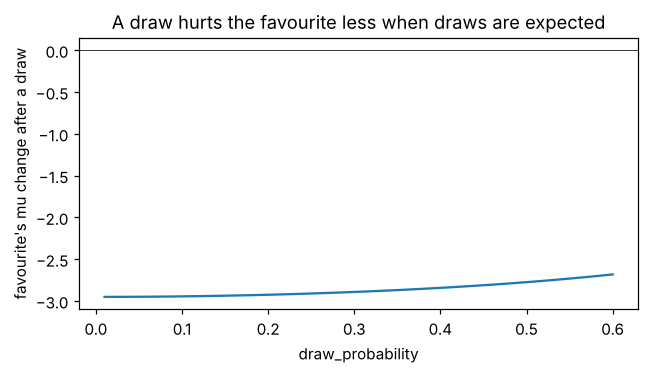

In [7]:
favourite, underdog = Rating(30, 5), Rating(20, 5)
ps = np.linspace(0.01, 0.6, 40)
change = [TS1(draw_probability=p).rate_1vs1(favourite, underdog, drawn=True)[0].mu - favourite.mu for p in ps]

plt.figure(figsize=(6, 3.5))
plt.plot(ps, change)
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("draw_probability")
plt.ylabel("favourite's mu change after a draw")
plt.title("A draw hurts the favourite less when draws are expected")
plt.tight_layout()

## 3. Partial play and match weight

- `partial_play`: the fraction of the match each player took part in (a substitute who played
  half the game learns half as much).
- `match_weight`: how much the whole match counts, in `[0, 1]` (e.g. 0.25 for a friendly).

In [8]:
env = TS1()
team_a, team_b = [Rating(), Rating()], [Rating(), Rating()]

(full_a1, full_a2), _ = env.rate([team_a, team_b])
(part_a1, part_a2), _ = env.rate([team_a, team_b], partial_play=[[1.0, 0.5], [1.0, 1.0]])
(light,), _ = env.rate([[Rating()], [Rating()]], match_weight=0.25)
(normal,), _ = env.rate([[Rating()], [Rating()]])

pd.DataFrame(
    {
        "full-time winner": [full_a1.mu, full_a1.sigma],
        "half-time winner (partial_play=0.5)": [part_a2.mu, part_a2.sigma],
        "1v1 winner, normal match": [normal.mu, normal.sigma],
        "1v1 winner, match_weight=0.25": [light.mu, light.sigma],
    },
    index=["mu", "sigma"],
).round(3)

,full-time winner,half-time winner (partial_play=0.5),"1v1 winner, normal match","1v1 winner, match_weight=0.25"
mu,28.108,27.837,29.396,26.365
sigma,7.774,8.132,7.171,7.991


## 4. Predictions and matchmaking

- `quality(teams)`: how balanced a match is (1 = perfectly even). Use it to pick opponents.
- `win_probabilities(teams)`: chance each team finishes first, for any number of teams.
- `outcome_probability(teams, ranks)`: probability of one exact result, draws included.

In [9]:
me = Rating(30, 3)
pool = {"ann": Rating(31, 2), "ben": Rating(22, 9), "cat": Rating(40, 1), "dan": Rating(29, 6)}

pd.DataFrame(
    {
        name: {"quality": sg.quality([[me], [r]]), "P(I win)": sg.win_probabilities([[me], [r]])[0]}
        for name, r in pool.items()
    }
).T.sort_values("quality", ascending=False).round(3)

,quality,P(I win)
ann,0.844,0.442
dan,0.656,0.545
ben,0.408,0.763
cat,0.288,0.067


In [10]:
# Who wins a 5-way race? Exact probabilities (not sampled), summing to 1.
racers = [[Rating(30, 2)], [Rating(28, 6)], [Rating(27, 1)], [Rating(25, 8)], [Rating(20, 3)]]
probs = sg.win_probabilities(racers)
pd.Series(probs, index=[f"racer {i+1} {r[0]}" for i, r in enumerate(racers)], name="P(finishes first)").round(4)

racer 1 Rating(mu=30.000, sigma=2.000)    0.3557
racer 2 Rating(mu=28.000, sigma=6.000)    0.2856
racer 3 Rating(mu=27.000, sigma=1.000)    0.1395
racer 4 Rating(mu=25.000, sigma=8.000)    0.2044
racer 5 Rating(mu=20.000, sigma=3.000)    0.0148
Name: P(finishes first), dtype: float64

In [11]:
# The three possible results of a 1v1, under a 25% draw rate, add up to 1.
football = TS1(draw_probability=0.25)
home, away = [Rating(27, 4)], [Rating(24, 5)]
results = {"home win": [0, 1], "draw": [0, 0], "away win": [1, 0]}
table = pd.Series({k: football.outcome_probability([home, away], ranks) for k, ranks in results.items()})
table["total"] = table.sum()
table.round(4)

home win    0.5513
draw        0.1611
away win    0.2876
total       1.0000
dtype: float64

## 5. Whole histories: `rate_matches`

Describe matches by player id and let the package track everyone's rating. The result holds the
final ratings and, if asked, each match's pre-match probability (useful for evaluation).

In [12]:
history = [
    Match([["ann", "ben"], ["cat", "dan"]], ranks=[0, 1]),
    Match([["ann"], ["cat"]], ranks=[0, 0]),                                   # a draw
    Match([["ben"], ["dan"], ["eve"]], ranks=[2, 0, 1]),                       # three-way race
    Match([["eve", "ann"], ["ben"]], ranks=[1, 0], partial_play=[[1.0, 0.5], [1.0]]),
    Match([["cat"], ["eve"]], ranks=[0, 1], match_weight=0.5),                 # a friendly
]
result = sg.rate_matches(history, with_probabilities=True)

board = pd.DataFrame(
    {name: {"mu": r.mu, "sigma": r.sigma, "leaderboard score": r.conservative()} for name, r in result.ratings.items()}
).T
print("pre-match probability of each actual result:", [round(p, 3) for p in result.probabilities])
board.sort_values("leaderboard score", ascending=False).round(2)

pre-match probability of each actual result: [0.478, 0.042, 0.068, 0.048, 0.703]


,mu,sigma,leaderboard score
ben,27.47,5.25,11.70
dan,29.65,6.14,11.23
cat,25.32,5.76,8.05
ann,22.20,5.88,4.56
eve,17.56,4.97,2.65


## 6. A simulated season: does it learn the truth?

We invent 200 players with hidden true skills, play 6,000 matches in mixed formats (1v1, 2v2,
1v2, 4-player free-for-alls) whose results follow the TrueSkill generative model, and check
what the ratings recover.

In [13]:
rng = np.random.default_rng(7)
env = TS1(draw_probability=0.10)
n_players, n_matches = 200, 6000
true_skill = rng.normal(25, 25 / 3, n_players)

def simulate_result(teams):
    """Ranks for a match, drawn from the model: performance = skill + noise, draws within the margin."""
    perf = [sum(true_skill[p] + rng.normal(0, env.beta) for p in team) for team in teams]
    order = np.argsort(perf)[::-1]
    ranks, r = [0] * len(teams), 0
    for k in range(1, len(order)):
        a, b = order[k - 1], order[k]
        if perf[a] - perf[b] > env.draw_margin(len(teams[a]) + len(teams[b])):
            r += 1
        ranks[b] = r
    return ranks

formats = [[1, 1], [2, 2], [1, 2], [1, 1, 1, 1]]
matches = []
for _ in range(n_matches):
    sizes = formats[rng.integers(len(formats))]
    ids = rng.choice(n_players, size=sum(sizes), replace=False).tolist()
    teams, i = [], 0
    for s in sizes:
        teams.append(ids[i : i + s])
        i += s
    matches.append(Match(teams, simulate_result(teams)))

t0 = time.time()
season = env.rate_matches(matches)
print(f"{n_matches} matches rated in {time.time() - t0:.1f} s")

6000 matches rated in 0.8 s


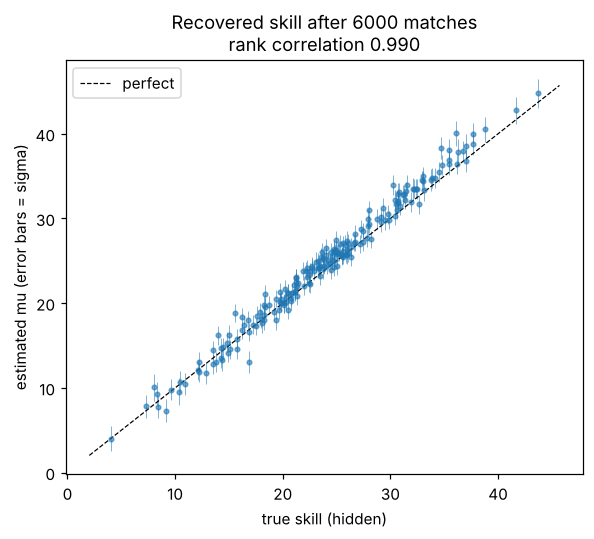

In [14]:
from scipy.stats import spearmanr

final = season.ratings
mus = np.array([final[p].mu for p in range(n_players)])
sigmas = np.array([final[p].sigma for p in range(n_players)])

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.errorbar(true_skill, mus, yerr=sigmas, fmt="o", ms=3, alpha=0.6, elinewidth=0.6)
lo, hi = true_skill.min() - 2, true_skill.max() + 2
ax.plot([lo, hi], [lo, hi], "k--", lw=0.8, label="perfect")
ax.set_xlabel("true skill (hidden)")
ax.set_ylabel("estimated mu (error bars = sigma)")
ax.set_title(f"Recovered skill after {n_matches} matches\nrank correlation {spearmanr(mus, true_skill).statistic:.3f}")
ax.legend()
plt.tight_layout()

### Watching beliefs sharpen

Replaying the season step by step lets us follow individual players and record, before each
2-team match, the probability the model gave the eventual winner.

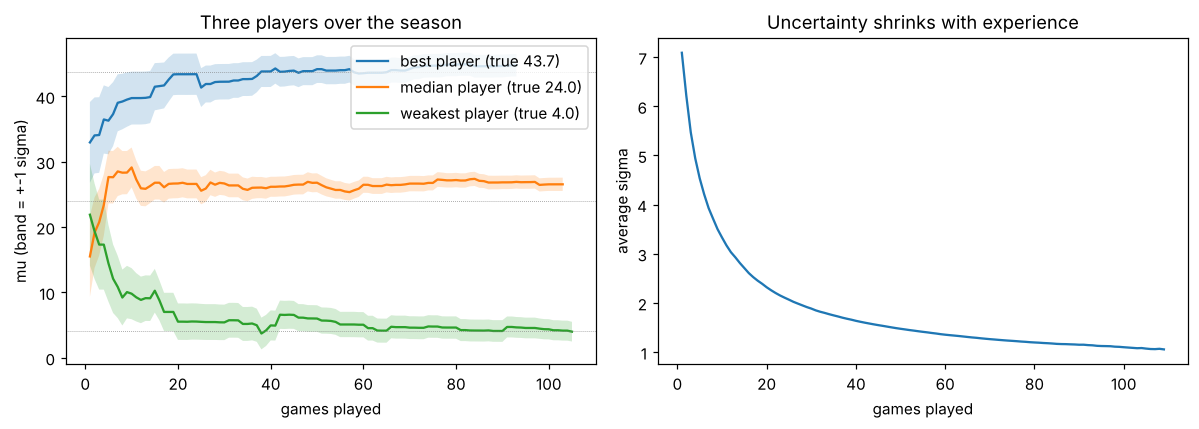

In [15]:
tracked = [int(np.argmax(true_skill)), int(np.argsort(true_skill)[n_players // 2]), int(np.argmin(true_skill))]
trajectory = {p: [] for p in tracked}
games_played = np.zeros(n_players, int)
sigma_by_games = {}
pred_win, observed = [], []

ratings = {}
for m in matches:
    teams = [[ratings.get(p, env.create_rating()) for p in t] for t in m.teams]
    if len(teams) == 2 and m.ranks[0] != m.ranks[1]:
        pred_win.append(env.outcome_probability(teams, [0, 1]))
        observed.append(m.ranks[0] < m.ranks[1])
    for ids, new in zip(m.teams, env.rate(teams, m.ranks)):
        for p, r in zip(ids, new):
            ratings[p] = r
            games_played[p] += 1
            sigma_by_games.setdefault(games_played[p], []).append(r.sigma)
            if p in trajectory:
                trajectory[p].append((games_played[p], r.mu, r.sigma))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for p, label in zip(tracked, ["best player", "median player", "weakest player"]):
    g, mu, sd = map(np.array, zip(*trajectory[p]))
    axes[0].plot(g, mu, label=f"{label} (true {true_skill[p]:.1f})")
    axes[0].fill_between(g, mu - sd, mu + sd, alpha=0.2)
    axes[0].axhline(true_skill[p], color="gray", lw=0.5, ls=":")
axes[0].set_xlabel("games played"); axes[0].set_ylabel("mu (band = +-1 sigma)"); axes[0].legend(); axes[0].set_title("Three players over the season")

g = sorted(k for k in sigma_by_games if len(sigma_by_games[k]) >= 20)
axes[1].plot(g, [np.mean(sigma_by_games[k]) for k in g])
axes[1].set_xlabel("games played"); axes[1].set_ylabel("average sigma"); axes[1].set_title("Uncertainty shrinks with experience")
plt.tight_layout()

### Are the predictions honest?

A calibrated model's "70% to win" should win about 70% of the time. We bin the 2-team
predictions and compare with what happened.

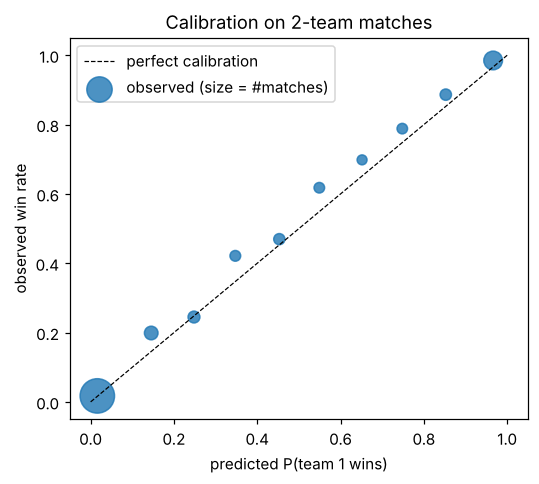

In [16]:
pred_win, observed = np.array(pred_win), np.array(observed, float)
bins = np.linspace(0, 1, 11)
centers, rates, counts = [], [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    sel = (pred_win >= lo) & (pred_win < hi)
    if sel.sum() >= 30:
        centers.append(pred_win[sel].mean()); rates.append(observed[sel].mean()); counts.append(int(sel.sum()))

plt.figure(figsize=(5, 4.5))
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect calibration")
plt.scatter(centers, rates, s=np.array(counts) / 4, alpha=0.8, label="observed (size = #matches)")
plt.xlabel("predicted P(team 1 wins)"); plt.ylabel("observed win rate"); plt.legend(); plt.title("Calibration on 2-team matches")
plt.tight_layout()

## 7. Choosing settings with data: log-loss

`outcome_probability` gives the probability the model assigned to what actually happened, so
the mean negative log-probability (log-loss) compares settings or models on the same matches.
Here the data were generated with `beta = sigma/2`, and that setting should win.

In [17]:
two_team = [m for m in matches if len(m.teams) == 2]
rows = {}
for label, beta in [("beta = sigma/4", 25 / 12), ("beta = sigma/2 (true)", 25 / 6), ("beta = sigma", 25 / 3)]:
    res = TS1(beta=beta, draw_probability=0.10).rate_matches(two_team, with_probabilities=True)
    rows[label] = -np.mean(np.log(res.probabilities))
pd.Series(rows, name="log-loss (lower is better)").round(4)

beta = sigma/4           0.4990
beta = sigma/2 (true)    0.4418
beta = sigma             0.4737
Name: log-loss (lower is better), dtype: float64

## 8. Built to not fall over

Extreme inputs that break textbook implementations: huge upsets, tiny draw margins, very
large free-for-alls, all 10^12-sd gaps. The engine stays finite, fast, and warns if the
message passing ever fails to converge (it does not, for anything realistic).

In [18]:
# A "million-sigma" upset: an all-but-impossible result. The model pulls both players a long way
# toward each other (as it must), and the maths stays finite.
print(sg.rate_1vs1(Rating(0, 1), Rating(1e6, 1)))

# 500-player free-for-all
big = [[Rating(float(m), 3.0)] for m in rng.normal(25, 8, 500)]
t0 = time.time(); out = sg.rate(big); dt = time.time() - t0
print(f"500-player FFA rated in {dt*1000:.0f} ms; winner {out[0][0]}, last place {out[-1][0]}")

# Throughput
a, b = Rating(), Rating(30, 4)
t0 = time.time()
for _ in range(20000):
    sg.rate_1vs1(a, b)
print(f"1v1 updates per second: {20000 / (time.time() - t0):,.0f}")

(Rating(mu=27410.228, sigma=0.990), Rating(mu=972589.772, sigma=0.990))
500-player FFA rated in 136 ms; winner Rating(mu=94.018, sigma=2.437), last place Rating(mu=-37.985, sigma=2.437)
1v1 updates per second: 88,287


## Where to go next

- `docs/ts1.md`: accuracy guarantees, fixes relative to other implementations, known limitations
  (e.g. sigmas are slightly overconfident; results depend on match order).
- `ROADMAP.md`: TrueSkill 2 (`sg.TS2`), parameter fitting on real data, evaluation harness.
- Everything in this notebook is covered by the test suite (`pytest`), including comparisons
  against independent reference implementations.